##### Master Degree in Computer Science and Data Science for Economics and Health

# What a network learns about words: internal representations

### Prof. Alfio Ferrara

## Introduction

In the previous notebook a neural network received the vector of a recipe and returned a probability distribution over the cuisines. We judged it by looking at its **output**: probabilities, labels, errors. Here we look **inside** the network.

The hidden layer of a network maps the input vector to a new vector, from which the output is computed. The input is **sparse**: one dimension for each term, almost all of them equal to zero. The hidden layer is **dense** and small, and the network has to build it by itself, because the only thing that we ask for is to predict the cuisine. What does it put there? If the layer is small enough to be drawn on a plane, we can look at it: each ingredient becomes a point, and we can ask which ingredients the network considers similar.

The answer is going to be a partial one, and this is the point of the notebook. The representation that the network builds is useful for the task: it captures **one aspect of the meaning** of an ingredient (which cuisine it points to), and not its meaning in general. Understanding why is the first step towards the next notebook, where we ask for a representation of the words that does not depend on a classification task.

We start from a toy example, small enough to see everything, and then we repeat the analysis on the real recipes.

## A toy example

Before using real recipes we build an invented problem. There are **three cuisines** (Mexican, Greek, Thai) and **twelve ingredients**: nine are *typical* of a cuisine, and three (`salt`, `oil`, `garlic`) are used everywhere. The typical ingredients belong to three **families**, and each cuisine has one ingredient of each family: for example, the citrus fruit is `lime` in the Mexican cuisine, `lemon` in the Greek one and `kaffir` in the Thai one.

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nlp.classification import LabelScheme, split
from nlp.representations import train_classifier, hidden_vectors, ingredient_vectors
from nlp.utils import show

cuisines = ["Mexican", "Greek", "Thai"]
families = ["citrus", "herb", "spice"]
signature = pd.DataFrame([["lime", "cilantro", "cumin"],
                          ["lemon", "oregano", "cinnamon"],
                          ["kaffir", "lemongrass", "galangal"]], index=cuisines, columns=families)
neutral = ["salt", "oil", "garlic"]

signature

,citrus,herb,spice
Mexican,lime,cilantro,cumin
Greek,lemon,oregano,cinnamon
Thai,kaffir,lemongrass,galangal


The recipes are generated by a simple rule: each typical ingredient of the cuisine of the recipe is present with probability 0.6, each typical ingredient of another cuisine with probability 0.05 (a little noise), and each neutral ingredient with probability 0.5. We generate 300 recipes for each cuisine.

This is a **construction, not evidence**: we built the example to isolate a mechanism, and the real recipes will tell whether the mechanism is there.

In [2]:
toy_terms = signature.to_numpy().ravel().tolist() + neutral
toy_index = {term: i for i, term in enumerate(toy_terms)}
rng = np.random.default_rng(0)

def toy_recipe(cuisine):
    present = []
    for other in cuisines:
        probability = 0.6 if other == cuisine else 0.05
        present += [term for term in signature.loc[other] if rng.random() < probability]
    return present + [term for term in neutral if rng.random() < 0.5]

y_toy = np.repeat(np.arange(len(cuisines)), 300)
toy_recipes = [toy_recipe(cuisines[c]) for c in y_toy]

X_toy = np.zeros((len(toy_recipes), len(toy_terms)), dtype=np.float32)
for r, recipe in enumerate(toy_recipes):
    for term in recipe:
        X_toy[r, toy_index[term]] = 1

for c in range(len(cuisines)):
    print(f"{cuisines[c]:8s}", ", ".join(toy_recipes[c * 300]))
toy_train, toy_validation, toy_test = split(y_toy)

Mexican  cilantro, cumin, lemon, garlic
Greek    lemon, oregano, salt, oil, garlic
Thai     kaffir, lemongrass, galangal, salt, garlic


### A network with two hidden neurons

The input is the multi-hot vector of the recipe (twelve coordinates, one for each ingredient: 1 if the ingredient is in the recipe, 0 otherwise) and the output is a probability distribution over the three cuisines. Between them there is a hidden layer of **two neurons**:

$$h = \mathrm{ReLU}(x W_1 + b_1) \qquad P(c \mid x) = \mathrm{softmax}(h W_2 + b_2)$$

With two neurons every recipe is mapped to a **point of the plane**, $h = (h_1, h_2)$, and the output layer has to decide the cuisine looking only at that point.

The same layer gives us a representation of each **ingredient**: the point in which the network puts a recipe that contains *only* that ingredient, that is, the vector $h$ that we get when $x$ has a single 1. This is what we are going to look at.

The initial weights are random and with two neurons the result can change from one run to another, so we train the network with five seeds and we keep the run with the lowest loss on the validation set. The test set is not used in the toy example.

In [3]:
runs = [train_classifier(X_toy[toy_train], y_toy[toy_train], X_toy[toy_validation], y_toy[toy_validation], units=2, seed=seed)
        for seed in range(5)]

pd.DataFrame({"best epoch": [r.epoch for r in runs],
              "validation loss": [r.validation_loss for r in runs],
              "validation accuracy": [r.validation_accuracy for r in runs]}).rename_axis("seed").style.format(
    {"validation loss": "{:.3f}", "validation accuracy": "{:.1%}"})

,best epoch,validation loss,validation accuracy
seed,,,
0,175,0.251,88.9%
1,167,0.301,87.2%
2,194,0.262,89.4%
3,205,0.265,89.4%
4,217,0.276,88.9%


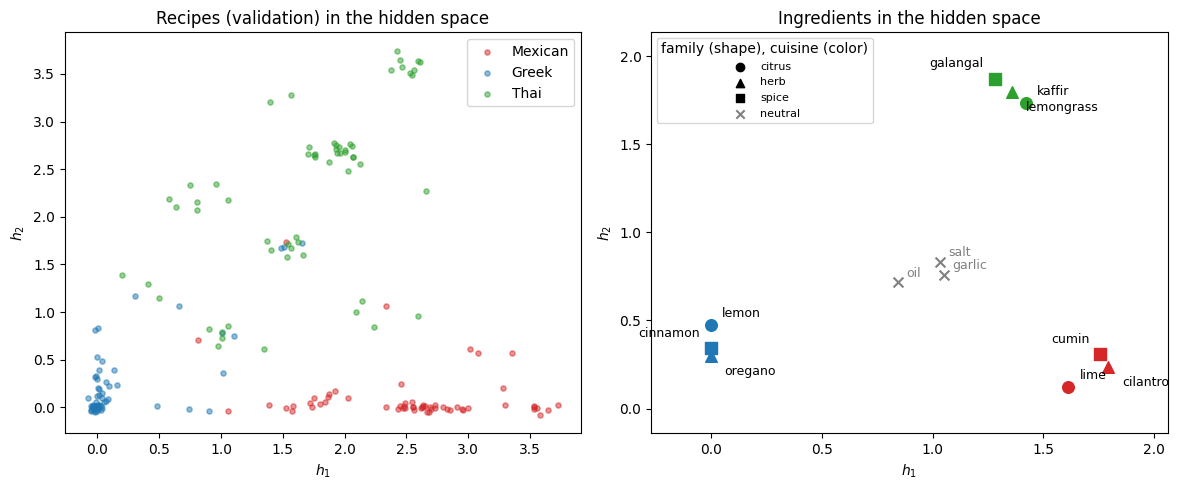

In [4]:
best = min(runs, key=lambda r: r.validation_loss)
H_recipes = hidden_vectors(best.model, X_toy[toy_validation])
H_terms = ingredient_vectors(best.model)

colors = {"Mexican": "tab:red", "Greek": "tab:blue", "Thai": "tab:green"}
markers = {"citrus": "o", "herb": "^", "spice": "s"}
offsets = {"citrus": (8, 6), "herb": (10, -14), "spice": (-8, 8)}

fig, ax = plt.subplots(ncols=2, figsize=(12, 5))
jitter = np.random.default_rng(1).normal(scale=0.03, size=H_recipes.shape)
for k, cuisine in enumerate(cuisines):
    selected = y_toy[toy_validation] == k
    ax[0].scatter(*(H_recipes[selected] + jitter[selected]).T, s=14, alpha=0.5, color=colors[cuisine], label=cuisine)
ax[0].set_title("Recipes (validation) in the hidden space")
ax[0].legend()

for cuisine in cuisines:
    for family in families:
        term = signature.loc[cuisine, family]
        x, y = H_terms[toy_index[term]]
        ax[1].scatter(x, y, marker=markers[family], s=70, color=colors[cuisine])
        ax[1].annotate(term, (x, y), textcoords="offset points", xytext=offsets[family], fontsize=9,
                       ha="right" if family == "spice" else "left")
for term in neutral:
    x, y = H_terms[toy_index[term]]
    ax[1].scatter(x, y, marker="x", s=50, color="gray")
    ax[1].annotate(term, (x, y), textcoords="offset points", xytext=(6, 4), fontsize=9, color="gray")
for family, marker in markers.items():
    ax[1].scatter([], [], marker=marker, color="black", label=family)
ax[1].scatter([], [], marker="x", color="gray", label="neutral")
ax[1].legend(title="family (shape), cuisine (color)", loc="upper left", fontsize=8)
ax[1].set_title("Ingredients in the hidden space")
ax[1].margins(0.15)
for a in ax:
    a.set_xlabel("$h_1$")
    a.set_ylabel("$h_2$")
plt.tight_layout()

In [5]:
positions = pd.DataFrame({family: [f"({H_terms[toy_index[signature.loc[c, family]]][0]:.2f}, "
                                   f"{H_terms[toy_index[signature.loc[c, family]]][1]:.2f})" for c in cuisines]
                          for family in families}, index=cuisines)
pd.concat([signature.add_suffix(" (term)"), positions.add_suffix(" (position)")], axis=1)[
    [f"{f} ({k})" for f in families for k in ["term", "position"]]]

,citrus (term),citrus (position),herb (term),herb (position),spice (term),spice (position)
Mexican,lime,"(1.61, 0.12)",cilantro,"(1.79, 0.24)",cumin,"(1.76, 0.31)"
Greek,lemon,"(0.00, 0.47)",oregano,"(0.00, 0.30)",cinnamon,"(0.00, 0.35)"
Thai,kaffir,"(1.42, 1.73)",lemongrass,"(1.36, 1.80)",galangal,"(1.28, 1.87)"


Two neurons are enough: the accuracy on the validation set is between 87.2% and 89.4% in the five runs (a random choice would give 33%). It is not higher because some recipes simply have no typical ingredient of their cuisine: with our rule it happens to 6.4% of them (0.4³), and a few of the others contain ingredients of another cuisine.

The left panel shows the recipes in the hidden space, each one at the point where the network has put it. The three cuisines occupy three different regions: the Greek recipes are near the origin, the Mexican ones are on the right at the bottom, the Thai ones are in the upper part. The output layer only has to separate these regions.

The right panel and the table show where the network has put the **ingredients**. The nine typical ingredients form **three groups, one for each cuisine**: the three Mexican ones are around (1.7, 0.2), the three Greek ones are on the vertical axis ($h_1 = 0$, the ReLU switches the first neuron off) and the three Thai ones are around (1.4, 1.8). The three neutral ingredients are in the middle, between the groups, because they do not point to any cuisine in particular.

Look now at the families. The three citrus fruits are in three different places: `lime` and `lemon` are both citrus fruits, but for the network they are about as far apart (1.65) as `lime` and `galangal` (1.78), which is a rhizome. And `lime` is much closer to `cumin` and `cilantro`, that have nothing in common with it except being used in the same cuisine. The network is not telling us what an ingredient *is*: it is telling us **what the ingredient says about the cuisine**. This is what the hidden layer needs, and nothing more. The question is whether the same happens with real recipes, where the structure is not designed by us.

## The real recipes

We now repeat the analysis on the real data. We use the same recipes and the same labels of the previous notebook: the **cuisine**, with its ten classes, and as text **only the list of the ingredients**, normalized with the same pipeline (lemmas, lowercase, no stop words, no punctuation).

In [6]:
import spacy

from nlp.preprocessing import TextNormalizer

with open("/Users/Flint/Data/recipes/foodcom/subsets/recipes_cuisine_tipo_10k.json") as f:
    recipes = json.load(f)

documents = [", ".join(r["ingredients"]) for r in recipes]

nlp = spacy.load("en_core_web_lg", disable=["parser", "ner"])
normalizer = TextNormalizer(lemmatize=True, remove_stopwords=True)
terms = [normalizer(doc) for doc in nlp.pipe(documents, batch_size=200)]

show(terms[0], width=90)

['black', 'bean', 'water', 'green', 'pepper', 'onion', 'garlic', 'clove', 'green',
 'pepper', 'olive', 'oil', 'salt', 'black', 'pepper', 'oregano', 'bay', 'leaf', 'sugar',
 'vinegar', 'white', 'wine', 'olive', 'oil', 'olive', 'oil', 'garlic', 'clove', 'water',
 'salt', 'rice']


In [7]:
indices, labels, classes = LabelScheme("cuisine").apply(recipes)
train, validation, test = split(labels)

pd.DataFrame({"recipes": [len(train), len(validation), len(test)]}, index=["train", "validation", "test"])

,recipes
train,3209
validation,1070
test,1070


### Vocabulary and multi-hot vectors

We keep **all the terms**. As in the previous notebook, the vocabulary is made of the terms that occur in at least two recipes of the training set (a term that occurs in a single recipe is useless for a model that has to generalize), and it is computed on the training set only. We choose the terms without using the labels, so the vocabulary does not already contain a hint about the cuisines.

Each recipe becomes a vector with one coordinate for each term, equal to 1 if the ingredient is in the recipe and 0 if it is not: a **multi-hot** vector, as in the toy example. We do not weight the terms with TF-IDF anymore: for a list of ingredients, the question is only whether an ingredient is there. Unlike the toy example, there are hundreds of terms, and we are going to look at only some of them.

In [8]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(analyzer=lambda t: t, min_df=2, binary=True)

def terms_of(positions):
    return [terms[indices[i]] for i in positions]

X_train = vectorizer.fit_transform(terms_of(train)).toarray().astype(np.float32)
X_validation = vectorizer.transform(terms_of(validation)).toarray().astype(np.float32)
X_test = vectorizer.transform(terms_of(test)).toarray().astype(np.float32)
y_train, y_validation, y_test = labels[train], labels[validation], labels[test]
vocabulary = vectorizer.get_feature_names_out()

recipes_per_term = X_train.sum(axis=0)
per_recipe = X_train.sum(axis=1)
print(f"Training matrix: {X_train.shape[0]} recipes x {X_train.shape[1]} terms")
print(f"Terms in a recipe: {per_recipe.mean():.1f} on average")
print(f"Recipes without any term of the vocabulary: {(per_recipe == 0).mean():.2%}")
print(f"Terms that occur in at least 30 training recipes: {(recipes_per_term >= 30).sum()}, "
      f"in at least 100: {(recipes_per_term >= 100).sum()}")

Training matrix: 3209 recipes x 768 terms
Terms in a recipe: 14.7 on average
Recipes without any term of the vocabulary: 0.00%
Terms that occur in at least 30 training recipes: 217, in at least 100: 98


The vocabulary has 768 terms, as in the previous notebook, and a recipe contains 14.7 of them on average (every recipe contains at least one). The matrix is the same one, with 0 and 1 in place of the TF-IDF weights.

Most of the terms are rare: only 217 occur in at least 30 training recipes and 98 in at least 100. This matters for what follows. The network learns the representation of a term from the recipes in which the term appears, so the representation of a rare term is based on a handful of examples and is not reliable. When we look at the ingredients we will consider only the terms that occur in at least 30 recipes.

## A hidden layer for the real recipes

The network is the same of the toy example, with a different size: 768 input coordinates, a hidden layer of $d$ neurons with ReLU, and ten outputs, one for each cuisine. The question is how large the hidden layer has to be. A layer with 2 neurons can be drawn, but with ten cuisines and 768 terms it has to throw away a lot of information. We train the network with several sizes, and for each size with five seeds, and we look at the validation set.

In [9]:
sizes = [2, 8, 16, 32, 64]
runs = {d: [train_classifier(X_train, y_train, X_validation, y_validation, units=d, seed=seed) for seed in range(5)]
        for d in sizes}

pd.DataFrame({d: {"accuracy, mean": np.mean([r.validation_accuracy for r in rs]),
                  "accuracy, min": min(r.validation_accuracy for r in rs),
                  "accuracy, max": max(r.validation_accuracy for r in rs),
                  "validation loss, mean": np.mean([r.validation_loss for r in rs])}
              for d, rs in runs.items()}).T.rename_axis("hidden neurons").style.format(
    {"accuracy, mean": "{:.1%}", "accuracy, min": "{:.1%}", "accuracy, max": "{:.1%}", "validation loss, mean": "{:.3f}"})

,"accuracy, mean","accuracy, min","accuracy, max","validation loss, mean"
hidden neurons,,,,
2,36.9%,31.7%,41.9%,1.712
8,63.1%,62.1%,64.9%,1.078
16,64.8%,63.7%,65.6%,1.015
32,65.4%,64.4%,65.8%,0.991
64,64.9%,63.9%,65.7%,0.991


With two neurons the accuracy is 36.9% on average and it changes a lot from one seed to another (from 31.7% to 41.9%): there is not enough room for ten cuisines, and this is why the toy example had only three. With 8 neurons the accuracy jumps to 63.1%, with 16 it reaches 64.8%, and then the curve is flat: 65.4% with 32 neurons and 64.9% with 64.

The differences from 16 neurons on are smaller than the variation between the seeds (the five runs with 16 neurons go from 63.7% to 65.6%), so we cannot say that a larger layer is better. We use **16 neurons**, the smallest size at which the accuracy stops improving. Notice what the network is doing: a recipe with 14.7 ingredients on average, described by 768 coordinates of which 14.7 are different from zero, is summarized by **16 numbers**, and the network has to decide on which information to keep.

In [10]:
from nlp.representations import class_distribution

d = 16
best = min(runs[d], key=lambda r: r.validation_loss)
H = ingredient_vectors(best.model)                          # one hidden vector for each term
P = class_distribution(best.model, np.eye(len(vocabulary)))  # P(cuisine | recipe with only that term)

frequent = np.where(recipes_per_term >= 30)[0]               # the terms that we look at
print(f"Hidden layer with {d} neurons, seed {runs[d].index(best)}: validation accuracy {best.validation_accuracy:.1%}")
print(f"{len(frequent)} terms in the plots")

Hidden layer with 16 neurons, seed 1: validation accuracy 64.6%
217 terms in the plots


### Looking at the ingredients

Each term is now a point of a 16-dimensional space, that we cannot draw. We project it on the plane with the **principal component analysis (PCA)**, which finds the two directions along which the points vary the most. The plane is a partial view: the two components keep only a part of the variance, and two points that are close in the plane may be far apart in the other dimensions.

In the plot each term has the color of the cuisine to which the network assigns a recipe that contains only that term (the cuisine with the highest probability), and the color is more intense when the network is more confident. We write the names of the terms that are farthest from the center of the plane.

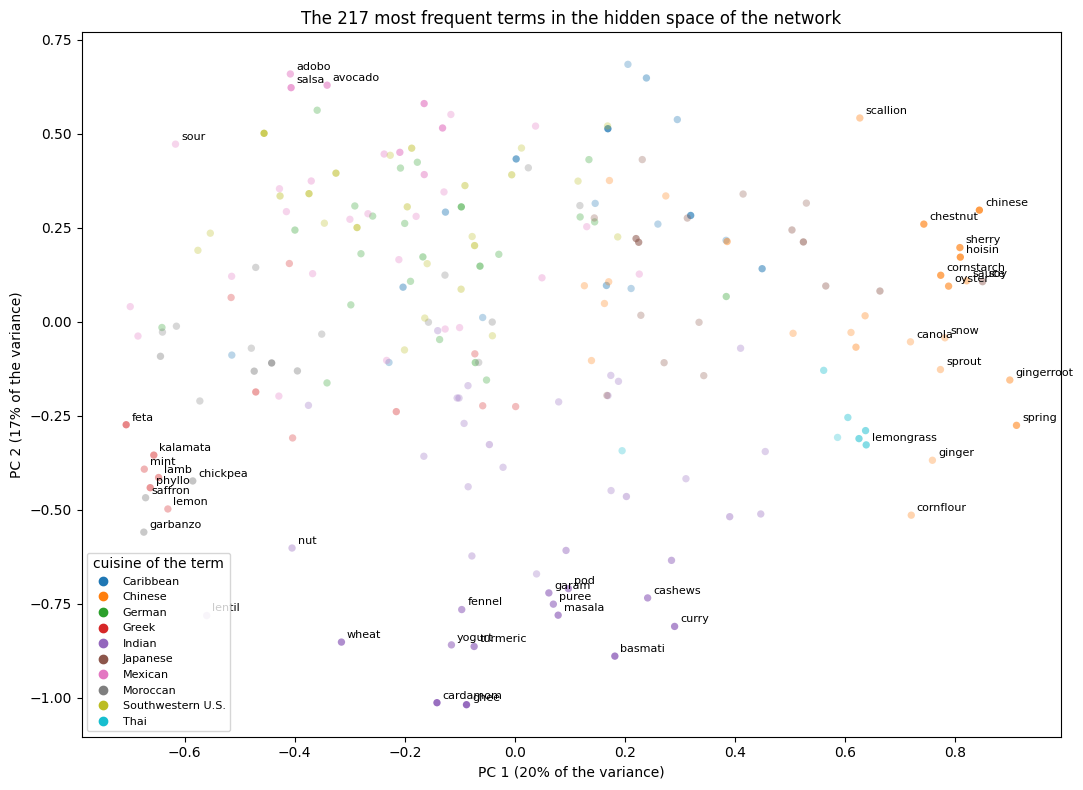

In [11]:
from matplotlib.lines import Line2D
from sklearn.decomposition import PCA

pca = PCA(n_components=2).fit(H[frequent])
Z = pca.transform(H[frequent])
top_class = P[frequent].argmax(axis=1)
confidence = np.clip((P[frequent].max(axis=1) - 0.1) / 0.4, 0.3, 1)
palette = plt.get_cmap("tab10")

fig, ax = plt.subplots(figsize=(11, 8))
for k, cuisine in enumerate(classes):
    selected = top_class == k
    ax.scatter(*Z[selected].T, s=28, color=palette(k), alpha=confidence[selected], edgecolors="none")

labelled = np.argsort(-np.linalg.norm(Z, axis=1))[:45]
for j in labelled:
    ax.annotate(vocabulary[frequent[j]], Z[j], textcoords="offset points", xytext=(4, 3), fontsize=8)
ax.legend([Line2D([], [], marker="o", linestyle="", color=palette(k)) for k in range(len(classes))], classes,
          title="cuisine of the term", loc="lower left", fontsize=8)
ax.set_xlabel(f"PC 1 ({pca.explained_variance_ratio_[0]:.0%} of the variance)")
ax.set_ylabel(f"PC 2 ({pca.explained_variance_ratio_[1]:.0%} of the variance)")
ax.set_title(f"The {len(frequent)} most frequent terms in the hidden space of the network")
plt.tight_layout()

The plane keeps 37% of the variance (20% and 17%), so it is a partial view, but the terms are not scattered at random: they form **regions that correspond to the cuisines**. The Indian terms are at the bottom (`cardamom`, `ghee`, `turmeric`, `masala`, `garam`, `curry`, `basmati`), the Greek and Moroccan ones are at the bottom left (`feta`, `kalamata`, `mint`, `lamb`, `phyllo`, `saffron`, `chickpea`), the Chinese and Japanese ones are on the right (`hoisin`, `sherry`, `oyster`, `cornstarch`, `scallion`) with the Thai `lemongrass` near them, and the Mexican ones are at the top left (`adobo`, `salsa`, `avocado`). In the middle there is a crowd of pale points: the terms that do not point to any cuisine in particular.

The names that we see are the terms farthest from the center, so they are, by construction, the ones with the strongest signal, and they are not a sample of the vocabulary. Some of them are fragments of the tokenization (`spring`, `snow`, `sprout`, `chinese`), as we have seen already.

Look at the neighborhoods, as we did in the toy example: `lemon` is next to `lamb`, `mint`, `kalamata` and `feta`, that are a meat, an herb, an olive and a cheese, and none of them is a fruit; `cardamom` is next to `ghee`, a fat. The network puts close the ingredients that **appear together in the same cuisine**, whatever they are. In the next section we measure it.

## Two kinds of similarity

The plot suggests that the network puts close the ingredients of the same cuisine. To measure it we need two references, that say what "similar" could mean for two ingredients.

- **The profile of a term**: among the training recipes that contain the term, how many belong to each cuisine. It is a distribution over the ten cuisines (we add one to each count, so that a rare term has no probability equal to zero) and it is what the data say about the term. Two terms are similar if their profiles are similar.
- **The vectors of spaCy**: the model that we used for the lemmas comes with a 300-dimensional vector for each word, that is built from a very large collection of general text and not from recipes. We use them as a reference for the **general** similarity between two words, without asking yet how they are made. They are not a ground truth: they are a different way of describing the words.

For each pair of the 217 frequent terms we compute the distance in the hidden space of the network, the distance between the profiles and the distance between the spaCy vectors, and we compare the rankings of the pairs with the **Spearman correlation**. We do it for the networks of all the sizes, with the five seeds.

In [12]:
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr

counts = X_train.T @ np.eye(len(classes))[y_train]                    # recipes of each cuisine that contain each term
profiles = (counts + 1) / (counts + 1).sum(axis=1, keepdims=True)

spacy_vectors = np.array([nlp.vocab[term].vector for term in vocabulary[frequent]])
spacy_vectors /= np.linalg.norm(spacy_vectors, axis=1, keepdims=True)

D_profile = pdist(np.sqrt(profiles[frequent]))
D_spacy = pdist(spacy_vectors)

rows = {}
for d, rs in runs.items():
    D_network = [pdist(ingredient_vectors(r.model)[frequent]) for r in rs]
    rows[d] = {"network and profiles": np.mean([spearmanr(D, D_profile)[0] for D in D_network]),
               "network and spaCy": np.mean([spearmanr(D, D_spacy)[0] for D in D_network])}
rows["spaCy and profiles"] = {"network and profiles": spearmanr(D_spacy, D_profile)[0]}

pd.DataFrame(rows).T.rename_axis("hidden neurons").style.format("{:.2f}", na_rep="")

,network and profiles,network and spaCy
hidden neurons,,
2,0.48,0.05
8,0.66,0.03
16,0.70,0.03
32,0.76,0.03
64,0.80,0.04
spaCy and profiles,0.10,


The distance between the terms in the hidden space follows the **profiles**: the correlation is 0.70 for the network with 16 neurons, and it grows with the size of the layer, from 0.48 with 2 neurons to 0.80 with 64. It does not follow **spaCy**: the correlation is between 0.03 and 0.05 for every size.

Two cautions. The two references are almost unrelated to each other (0.10 between the profiles and spaCy), so a representation that follows one has little reason to follow the other, and the near-zero correlation with spaCy is less surprising than it looks: it says that the network is closer to one description than to the other, and not that spaCy is the right one. And a correlation tells *how much*, not *what*: for this reason we now look at the terms.

## Why does the network do this?

There are three things to notice.

**In the input there is no similarity.** In a multi-hot vector every term has its own coordinate, and two different terms are always at the same distance, whatever they are: `lime` is as far from `lemon` as from `tortilla`. The idea of "similar ingredients" does not exist in the input. It appears only in the hidden layer, because the terms have to share a small number of dimensions, and the network has to decide who goes next to whom.

**The only thing that tells the network who goes next to whom is the cuisine.** The vector of a term changes during the training because of the errors of the output on the recipes that contain the term, carried back through the output layer. Two terms that occur in recipes of the same cuisine receive the same kind of push, and they end up in the same region of the space. Nothing else enters: the network never sees that `lime` and `lemon` are both citrus fruits, because this is not information that helps to guess the cuisine.

**More room makes the representation more faithful to the task, not more general.** The table above shows it: with more neurons the distance between the terms is closer to the distance between their profiles (the correlation goes from 0.48 with 2 neurons to 0.80 with 64) while the correlation with spaCy stays around zero for every size. A small layer is not what makes the representation specific to the task: with 2 neurons the picture of the cuisines is only *coarser*. The cause is what the training asks for.

This is an explanation supported by the table, and not a proof: the direct test would be to change what the network is asked to do and to see the terms move. This is what we do in the next notebook.

## Clustering with two sets of vectors

Correlation is a number. To see what is different we group the 217 terms in 15 **clusters** with the k-means algorithm, twice: once with the vectors of our network (16 neurons) and once with the vectors of spaCy. Then we look at some terms, and at the terms that the two groupings put with them.

In [13]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

frequent_profiles = profiles[frequent]

def cluster_purity(assignment):
    """How much of the profile of the terms is on the main cuisine of their cluster (a random grouping gives about 0.15)."""
    total = 0
    for g in np.unique(assignment):
        members = assignment == g
        main_cuisine = frequent_profiles[members].mean(axis=0).argmax()
        total += frequent_profiles[members][:, main_cuisine].sum()
    return total / len(assignment)

def kmeans(vectors, k):
    return KMeans(n_clusters=k, n_init=20, random_state=0).fit_predict(vectors)

rows = {}
for k in [10, 15, 20]:
    ours, theirs = kmeans(H[frequent], k), kmeans(spacy_vectors, k)
    random = np.random.default_rng(0).integers(0, k, len(frequent))
    rows[k] = {"agreement of the two groupings (ARI)": adjusted_rand_score(ours, theirs),
               "purity, network": cluster_purity(ours), "purity, spaCy": cluster_purity(theirs),
               "purity, random groups": cluster_purity(random)}
pd.DataFrame(rows).T.rename_axis("clusters").style.format("{:.2f}")

,agreement of the two groupings (ARI),"purity, network","purity, spaCy","purity, random groups"
clusters,,,,
10,0.03,0.29,0.17,0.15
15,0.05,0.29,0.19,0.15
20,0.04,0.30,0.19,0.16


The two groupings are almost unrelated: the adjusted Rand index is between 0.03 and 0.05, where 0 is the agreement that we would have with two random groupings. The groups of the network are much more homogeneous with respect to the cuisine: the purity is between 0.29 and 0.30, against 0.17-0.19 for spaCy and 0.15-0.16 for random groups, so the groups of spaCy are only slightly more homogeneous than random ones. The purity of the network is low in absolute terms because many terms do not point to any cuisine. The picture is the same with 10, 15 and 20 clusters (we have read the clusters only with 15).

In [14]:
k = 15
clusters_network, clusters_spacy = kmeans(H[frequent], k), kmeans(spacy_vectors, k)
names = vocabulary[frequent]

def companions(term, clusters, vectors, n=8):
    """The terms of the cluster of `term`, from the closest to the farthest."""
    i = list(names).index(term)
    others = [j for j in np.where(clusters == clusters[i])[0] if j != i]
    others.sort(key=lambda j: np.linalg.norm(vectors[j] - vectors[i]))
    return ", ".join(names[j] for j in others[:n])

chosen = ["lemon", "cilantro", "coriander", "cumin", "feta", "tofu", "garam", "chicken", "vanilla"]
table = pd.DataFrame({"with the vectors of the network": [companions(t, clusters_network, H[frequent]) for t in chosen],
                      "with the vectors of spaCy": [companions(t, clusters_spacy, spacy_vectors) for t in chosen]},
                     index=pd.Index(chosen, name="term"))
table.style.set_properties(**{"text-align": "left"}).set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])

,with the vectors of the network,with the vectors of spaCy
term,,
lemon,"phyllo, mint, kalamata, lamb, chickpea, garbanzo, parsley, rind","lime, pineapple, cinnamon, juice, vanilla, mango, coconut, rind"
cilantro,"chili, chilie, chile, yellow, granulated, kernel, jack, monterey","parsley, basil, coriander, oregano, garlic, dill, onion, paprika"
coriander,"turmeric, fennel, nut, garam, pod, masala, puree, basmati","cilantro, fennel, paprika, thyme, parsley, lemongrass, basil, pepper"
cumin,"ground, stick, tomato, raisin, powdered, fat, sausage, bay","garam, turmeric, cardamom, ghee, saffron, masala, basmati, chilie"
feta,"phyllo, kalamata, rind, lemon, lamb, mint, pasta, romaine","spinach, parmesan, zucchini, kalamata, romaine, eggplant, lettuce, tomato"
tofu,"firm, sesame, soy, steak, rice, sake, sodium, mirin","sauce, chicken, curry, pork, cheese, bacon, pasta, beef"
garam,"masala, puree, pod, turmeric, basmati, fennel, ghee, cardamom","masala, cumin, turmeric, cardamom, ghee, basmati, saffron, chilie"
chicken,"green, garlic, light, bean, water, flake, stew, virgin","pork, beef, sauce, steak, turkey, sausage, bacon, shrimp"
vanilla,"pepper, bake, soda, oregano, dry, celery, margarine, lean","cinnamon, lemon, coconut, pineapple, spice, sour, banana, honey"


The table is the core of the section, and the two columns answer two different questions.

- **`cilantro` and `coriander`** are the leaves and the seeds of the same plant. The network keeps them apart: `cilantro` is with `chili`, `jack`, `monterey`, `coriander` is with `turmeric`, `garam`, `masala`, `basmati`. spaCy puts them together, among the herbs and the spices (`parsley`, `basil`, `fennel`).
- **`lemon`** is with `phyllo`, `mint`, `kalamata`, `lamb` for the network, and with `lime`, `pineapple`, `mango`, `vanilla` for spaCy: for the network a Greek ingredient, for spaCy a fruit.
- **`feta`**: for the network it belongs to a Greek table (`phyllo`, `kalamata`, `lemon`, `lamb`), for spaCy to a cheese and vegetables (`parmesan`, `spinach`, `zucchini`, `eggplant`).
- **`tofu`** is with `soy`, `sesame`, `sake`, `mirin` for the network, and with `chicken`, `pork`, `beef`, `bacon` for spaCy.
- **`garam`** is the term on which the two columns agree (`masala`, `turmeric`, `basmati`, `ghee`, `cardamom`): it is specific to a cuisine *and* it is a specific kind of thing.
- **`cumin`** has no place in the network: its companions are `ground`, `stick`, `bay`, without a cuisine. The reason is in the data: it occurs in the recipes of several cuisines (28% of its recipes are Moroccan, 24% Indian, 17% Mexican), so it does not say much about any of them. spaCy puts it with the Indian spices (`garam`, `turmeric`, `cardamom`, `ghee`).
- **`chicken`** and **`vanilla`** are the same case: for the network they have no companions that make sense (`green`, `garlic`, `light` for `chicken`; `pepper`, `bake`, `soda` for `vanilla`), because `chicken` is almost equally likely in every cuisine; for spaCy they are with other meats and with other sweet flavors.

## What is different, and what is missing

The two sets of vectors describe two different things.

- The vectors of the **network** say which ingredients *behave in the same way with respect to the cuisine*. `Lemon` and `lamb` are neighbors because they appear in the same kind of recipes, and not because they are similar things. A term that is used in many cuisines (`cumin`, `chicken`) has no place, because the task does not need one.
- The vectors of **spaCy** say which words *are used in similar ways in the language*: `lemon` with `lime`, `chicken` with `pork`, `cilantro` with `coriander`. They do not know anything about the cuisines, and they place `feta` among the vegetables because in general text this is where it is found.

Both are a part of what we would call the meaning of an ingredient, and none of them is all of it. Some questions for the discussion. Which grouping is closer to the meaning of `lemon`? Is there a task for which the network would put `lime` and `lemon` together? If we asked the network to predict the *type* of dish (dessert, soup, ...) instead of the cuisine, where would `lemon` go?

In [15]:
P_test = class_distribution(best.model, X_test)
units = best.model[0].out_features
print(f"Test accuracy of the network with {units} neurons: {(P_test.argmax(axis=1) == y_test).mean():.1%}")

Test accuracy of the network with 16 neurons: 65.1%


The test set is used only here, once, and we have not changed anything after looking at it: the notebook is about what the network learns, not about how well it classifies.

We started from the observation that a classifier has to build a dense representation of its input, and we have seen that this representation is **shaped by the task**: it keeps what is useful to decide the cuisine and nothing else. The representation that spaCy gives us is different, and it was built **without any label**: nobody told the model that `lemon` is similar to `lime`. This is the question that we leave open, and that the next notebook answers: *how can we build the representation of a word from the text alone, so that it captures what the word means in general and not what it says about one particular task?* The answer starts from a simple idea, that a word is characterized by the **company it keeps**: its context.